<a href="https://colab.research.google.com/github/shivadesaboyina/Calibo_Assignment_VIS/blob/main/Siva_DataVisualizationEDA_Original.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)

DATA_FILE = "messy_ecommerce_15000_student_practice.csv"
orders = pd.read_csv(DATA_FILE)

print("Loaded dataset successfully")
print(orders.head())


Loaded dataset successfully
    Order_ID Customer_ID   Age  Gender       City Product_Category  \
0  ORD106680    CUST7362  28.0    Male  Hyderabad          Fashion   
1  ORD103291    CUST3155  30.0  Female      Delhi          Fashion   
2  ORD106559    CUST1349  32.0    Male       Pune           Sports   
3  ORD107927    CUST6779  39.0  Female    Chennai      Electronics   
4  ORD105665    CUST1389  27.0    Male    Chennai      Electronics   

      Product  Quantity  Unit_Price  Discount Payment_Method  Order_Date  \
0       Shoes         2     2507.76      15.0     Debit Card  2025-08-27   
1       Jeans         2     1988.04      25.0     Debit Card  2025-06-18   
2    Yoga Mat         2      776.35      15.0            UPI  2025-01-13   
3  Smartwatch         1     7739.89      10.0            UPI  2026-06-01   
4      Laptop         1    61138.76       5.0     Debit Card  2026-06-17   

   Rating  Delivery_Days Returned  Total_Amount  
0     4.1            7.0       No       4263

In [5]:
rows, cols = orders.shape
print(f"Number of observations : {rows:,}")
print(f"Number of variables   : {cols}")
print("\nColumn names:")
print(list(orders.columns))


Number of observations : 15,075
Number of variables   : 16

Column names:
['Order_ID', 'Customer_ID', 'Age', 'Gender', 'City', 'Product_Category', 'Product', 'Quantity', 'Unit_Price', 'Discount', 'Payment_Method', 'Order_Date', 'Rating', 'Delivery_Days', 'Returned', 'Total_Amount']


In [6]:
type_report = pd.DataFrame({
    "dtype": orders.dtypes.astype(str),
    "missing": orders.isna().sum(),
    "missing_pct": (orders.isna().mean() * 100).round(2),
    "unique_values": orders.nunique(dropna=True)
})
print(type_report)


                    dtype  missing  missing_pct  unique_values
Order_ID           object        0         0.00          15000
Customer_ID        object        0         0.00           6795
Age               float64      271         1.80             54
Gender             object      179         1.19              5
City               object      150         1.00             12
Product_Category   object        0         0.00              6
Product            object        0         0.00             30
Quantity            int64        0         0.00              5
Unit_Price        float64        0         0.00          14759
Discount          float64      121         0.80              7
Payment_Method     object      226         1.50              8
Order_Date         object        0         0.00            730
Rating            float64      381         2.53             40
Delivery_Days     float64      180         1.19             13
Returned           object        0         0.00        

## 3. Numeric Profile

In [7]:
numeric_fields = orders.select_dtypes(include=np.number).columns.tolist()
summary = orders[numeric_fields].describe().T
summary["range"] = summary["max"] - summary["min"]
print(summary.round(2))


                 count      mean       std     min      25%      50%      75%  \
Age            14804.0     32.32      9.02    5.00    26.00    32.00    38.00   
Quantity       15075.0      1.90      1.08    1.00     1.00     2.00     2.00   
Unit_Price     15075.0   7409.18  13950.01  425.61  1248.32  2480.28  3811.46   
Discount       14954.0     12.02      7.70    0.00     5.00    10.00    15.00   
Rating         14694.0      3.87      0.74    1.00     3.40     3.90     4.40   
Delivery_Days  14895.0      4.49      1.96    1.00     3.00     4.00     6.00   
Total_Amount   15075.0  12553.36  29550.80  298.27  1742.20  3223.75  7739.26   

                      max       range  
Age                 99.00       94.00  
Quantity             5.00        4.00  
Unit_Price      309655.38   309229.77  
Discount            30.00       30.00  
Rating               5.00        4.00  
Delivery_Days       14.00       13.00  
Total_Amount   1238621.52  1238323.25  


In [8]:
key_stats = orders[numeric_fields].agg(["mean", "median", "std", "min", "max"]).T
print(key_stats.round(2))


                   mean   median       std     min         max
Age               32.32    32.00      9.02    5.00       99.00
Quantity           1.90     2.00      1.08    1.00        5.00
Unit_Price      7409.18  2480.28  13950.01  425.61   309655.38
Discount          12.02    10.00      7.70    0.00       30.00
Rating             3.87     3.90      0.74    1.00        5.00
Delivery_Days      4.49     4.00      1.96    1.00       14.00
Total_Amount   12553.36  3223.75  29550.80  298.27  1238621.52


The median Total Amount is much lower than its mean, while Unit Price also has a wide range. That difference is a useful signal to investigate skewness and unusually large transactions rather than relying on the mean alone.

## 4. Categorical Profile

In [9]:
categorical_fields = orders.select_dtypes(exclude=np.number).columns.tolist()
for field in categorical_fields:
    print(f"\n--- {field} ---")
    print("Unique:", orders[field].nunique(dropna=True))
    print(orders[field].value_counts(dropna=False).head(10))



--- Order_ID ---
Unique: 15000
Order_ID
ORD105971    2
ORD107827    2
ORD100765    2
ORD105170    2
ORD114425    2
ORD112666    2
ORD100863    2
ORD103372    2
ORD103685    2
ORD101796    2
Name: count, dtype: int64

--- Customer_ID ---
Unique: 6795
Customer_ID
CUST5659    8
CUST8696    8
CUST6143    8
CUST4808    8
CUST1881    8
CUST1345    8
CUST4633    8
CUST2697    7
CUST3244    7
CUST4612    7
Name: count, dtype: int64

--- Gender ---
Unique: 5
Gender
Female    7292
Male      7023
Other      441
NaN        179
male        80
female      60
Name: count, dtype: int64

--- City ---
Unique: 12
City
Kolkata          1274
Vijayawada       1271
Ahmedabad        1268
Pune             1263
Guntur           1251
Hyderabad        1241
Bengaluru        1237
Warangal         1235
Delhi            1234
Visakhapatnam    1230
Name: count, dtype: int64

--- Product_Category ---
Unique: 6
Product_Category
Electronics       3815
Fashion           3296
Home & Kitchen    2707
Beauty            2147
S

In [10]:
category_columns = ["Gender", "City", "Product_Category", "Product", "Payment_Method", "Returned"]

for field in category_columns:
    orders[field] = orders[field].astype("string").str.strip()

# Only fields with known case-sensitive duplicates are normalized here.
orders["Gender"] = orders["Gender"].str.title()
orders["Payment_Method"] = orders["Payment_Method"].str.title()
orders["Returned"] = orders["Returned"].str.title()

print("Gender values:", orders["Gender"].dropna().unique())
print("Payment methods:", orders["Payment_Method"].dropna().unique())
print("Return labels:", orders["Returned"].dropna().unique())


Gender values: <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: string
Payment methods: <StringArray>
['Debit Card', 'Upi', 'Cod', 'Net Banking', 'Credit Card', 'Wallet']
Length: 6, dtype: string
Return labels: <StringArray>
['No', 'Yes']
Length: 2, dtype: string


## 6. Missing-Value Investigation

In [11]:
missing_table = pd.DataFrame({
    "missing_count": orders.isna().sum(),
    "missing_percent": (orders.isna().mean() * 100).round(2)
}).query("missing_count > 0").sort_values("missing_count", ascending=False)
print(missing_table)


                missing_count  missing_percent
Rating                    381             2.53
Age                       271             1.80
Payment_Method            226             1.50
Delivery_Days             180             1.19
Gender                    179             1.19
City                      150             1.00
Discount                  121             0.80


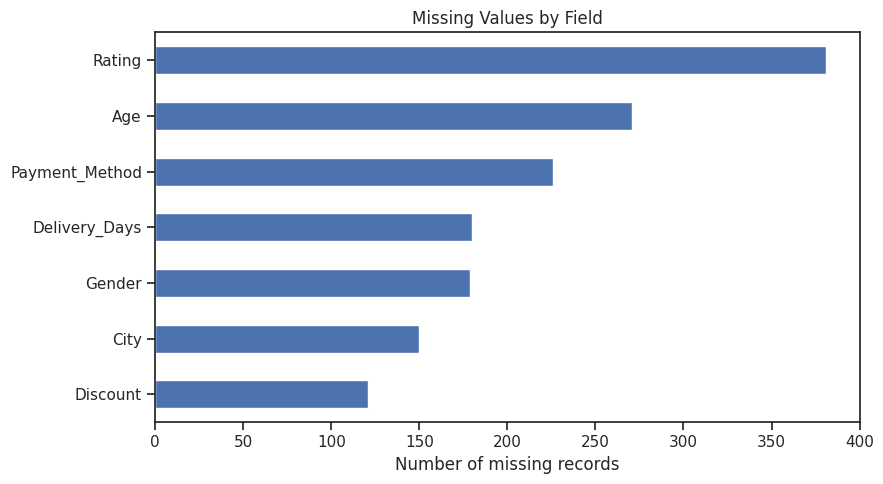

In [12]:
# Visual snapshot of fields containing missing observations
if not missing_table.empty:
    ax = missing_table["missing_count"].sort_values().plot(kind="barh", title="Missing Values by Field")
    ax.set_xlabel("Number of missing records")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()


In [13]:
median_fill = ["Age", "Discount", "Rating", "Delivery_Days"]
mode_fill = ["Gender", "City", "Payment_Method"]

for field in median_fill:
    orders[field] = orders[field].fillna(orders[field].median())

for field in mode_fill:
    orders[field] = orders[field].fillna(orders[field].mode(dropna=True).iloc[0])

print("Remaining missing values:", int(orders.isna().sum().sum()))


Remaining missing values: 0


In [14]:
duplicate_rows = orders.duplicated()
print("Exact duplicate rows:", int(duplicate_rows.sum()))
print("Repeated Order_ID values:", int(orders["Order_ID"].duplicated().sum()))

if duplicate_rows.any():
    display(orders.loc[duplicate_rows].head())


Exact duplicate rows: 75
Repeated Order_ID values: 75


,Order_ID,Customer_ID,Age,Gender,City,Product_Category,Product,Quantity,Unit_Price,Discount,Payment_Method,Order_Date,Rating,Delivery_Days,Returned,Total_Amount
232,ORD100933,CUST7882,38.0,Female,Vijayawada,Fashion,Shoes,2,2815.57,5.0,Upi,2026-06-25,5.0,6.0,No,5349.58
1123,ORD103976,CUST3601,67.0,Male,Ahmedabad,Electronics,Headphones,1,3002.35,20.0,Upi,2026-09-03,3.8,7.0,No,2401.88
1274,ORD107827,CUST1775,39.0,Female,Ahmedabad,Sports,Cricket Bat,1,3188.13,5.0,Upi,2026-04-02,2.8,4.0,No,3028.72
2255,ORD111361,CUST7933,25.0,Male,Kolkata,Sports,Dumbbells,3,2207.60,15.0,Wallet,2025-09-29,5.0,3.0,No,5629.37
2311,ORD101796,CUST5636,43.0,Male,Pune,Fashion,T-Shirt,2,914.82,10.0,Net Banking,2026-07-16,3.3,5.0,No,1646.67


In [15]:
before_drop = len(orders)
orders = orders.drop_duplicates().copy()
print(f"Rows before duplicate removal: {before_drop}")
print(f"Rows after duplicate removal : {len(orders)}")


Rows before duplicate removal: 15075
Rows after duplicate removal : 15000


In [16]:
orders["Order_Date"] = pd.to_datetime(orders["Order_Date"], errors="coerce")
print("Date type:", orders["Order_Date"].dtype)
print("Date range:", orders["Order_Date"].min(), "to", orders["Order_Date"].max())
print("Invalid dates after conversion:", int(orders["Order_Date"].isna().sum()))


Date type: datetime64[ns]
Date range: 2025-01-01 00:00:00 to 2026-12-31 00:00:00
Invalid dates after conversion: 0


In [17]:
orders["Calculated_Total"] = (
    orders["Unit_Price"] * orders["Quantity"] *
    (1 - orders["Discount"] / 100)
)
orders["Amount_Gap"] = orders["Total_Amount"] - orders["Calculated_Total"]

print(orders[["Total_Amount", "Calculated_Total", "Amount_Gap"]].head())
print("\nLarge absolute gaps (> 1000):", int((orders["Amount_Gap"].abs() > 1000).sum()))


   Total_Amount  Calculated_Total  Amount_Gap
0       4263.19          4263.192      -0.002
1       2982.06          2982.060       0.000
2       1319.80          1319.795       0.005
3       6965.90          6965.901      -0.001
4      58081.82         58081.822      -0.002

Large absolute gaps (> 1000): 17


In [18]:
def iqr_summary(frame, field):
    q1 = frame[field].quantile(0.25)
    q3 = frame[field].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((frame[field] < lower) | (frame[field] > upper)).sum()
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "lower": lower, "upper": upper, "outlier_count": count})

outlier_fields = ["Age", "Unit_Price", "Quantity", "Discount", "Rating", "Delivery_Days", "Total_Amount"]
outlier_table = pd.DataFrame({field: iqr_summary(orders, field) for field in outlier_fields}).T
print(outlier_table.round(2))


                    Q1       Q3      IQR    lower     upper  outlier_count
Age              26.00    38.00    12.00     8.00     56.00           90.0
Unit_Price     1249.04  3819.30  2570.26 -2606.35   7674.68         2401.0
Quantity          1.00     2.00     1.00    -0.50      3.50         1513.0
Discount          5.00    15.00    10.00   -10.00     30.00            0.0
Rating            3.40     4.40     1.00     1.90      5.90           73.0
Delivery_Days     3.00     6.00     3.00    -1.50     10.50           24.0
Total_Amount   1741.91  7741.01  5999.10 -7256.74  16739.66         2472.0


In [19]:
print("Rows:", len(orders))
print("Columns:", orders.shape[1])
print("Missing cells:", int(orders.isna().sum().sum()))
print("Exact duplicates:", int(orders.duplicated().sum()))
print("Date dtype:", orders["Order_Date"].dtype)


Rows: 15000
Columns: 18
Missing cells: 0
Exact duplicates: 0
Date dtype: datetime64[ns]


In [20]:
clean_orders = orders.drop(columns=["Calculated_Total", "Amount_Gap"])
clean_orders.to_csv("cleaned_ecommerce_dataset_original_analysis.csv", index=False)
print("Clean dataset saved successfully.")


Clean dataset saved successfully.


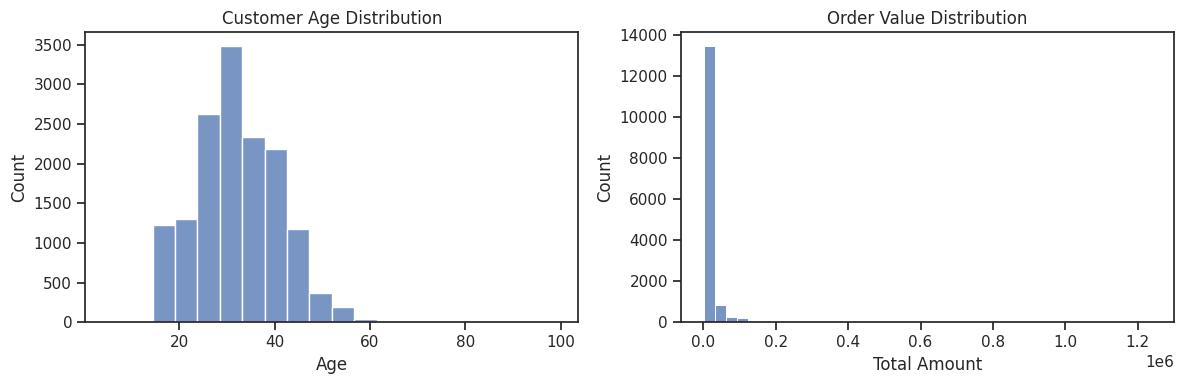

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(orders["Age"], bins=20, ax=axes[0])
axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age")

sns.histplot(orders["Total_Amount"], bins=40, ax=axes[1])
axes[1].set_title("Order Value Distribution")
axes[1].set_xlabel("Total Amount")
plt.tight_layout()
plt.show()


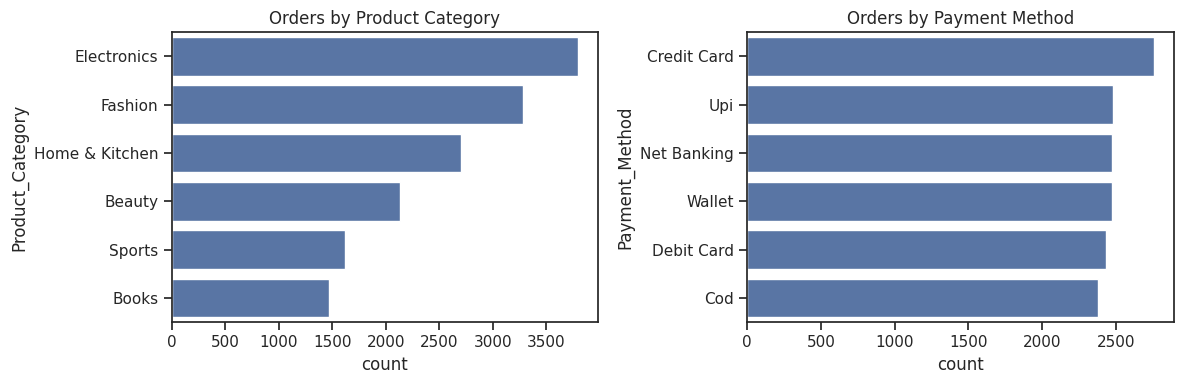

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=orders, y="Product_Category", order=orders["Product_Category"].value_counts().index, ax=axes[0])
axes[0].set_title("Orders by Product Category")

sns.countplot(data=orders, y="Payment_Method", order=orders["Payment_Method"].value_counts().index, ax=axes[1])
axes[1].set_title("Orders by Payment Method")
plt.tight_layout()
plt.show()


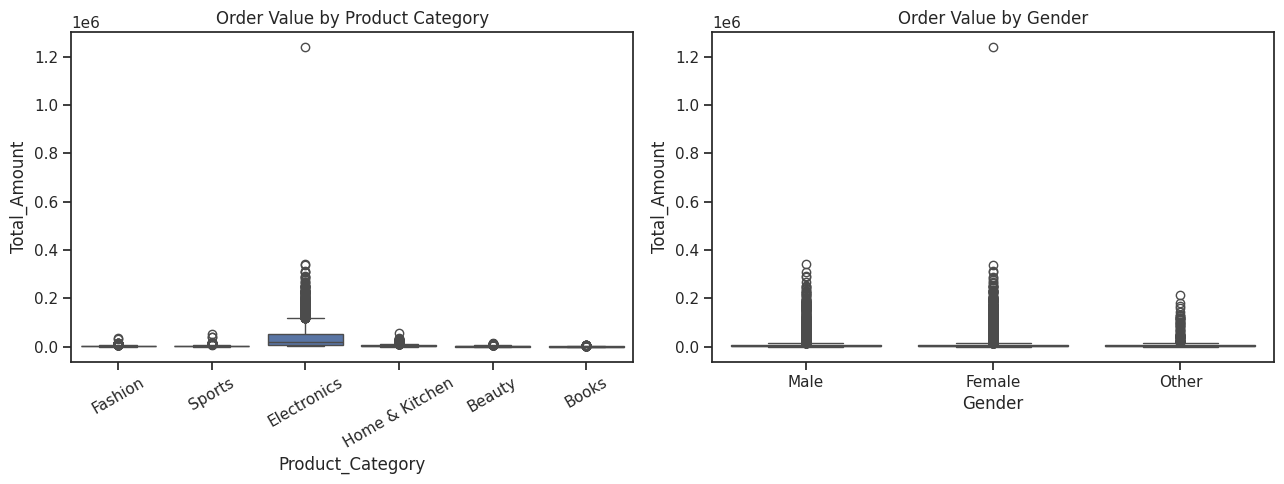

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=orders, x="Product_Category", y="Total_Amount", ax=axes[0])
axes[0].set_title("Order Value by Product Category")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=orders, x="Gender", y="Total_Amount", ax=axes[1])
axes[1].set_title("Order Value by Gender")
plt.tight_layout()
plt.show()


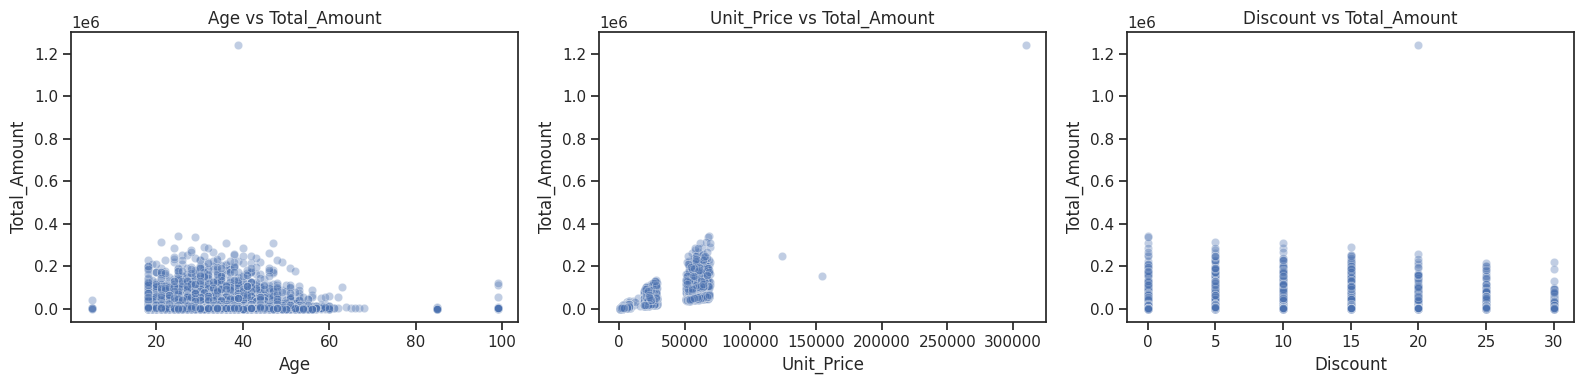

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
relationships = [("Age", "Total_Amount"), ("Unit_Price", "Total_Amount"), ("Discount", "Total_Amount")]
for ax, (x, y) in zip(axes, relationships):
    sns.scatterplot(data=orders, x=x, y=y, alpha=0.35, ax=ax)
    ax.set_title(f"{x} vs {y}")
plt.tight_layout()
plt.show()


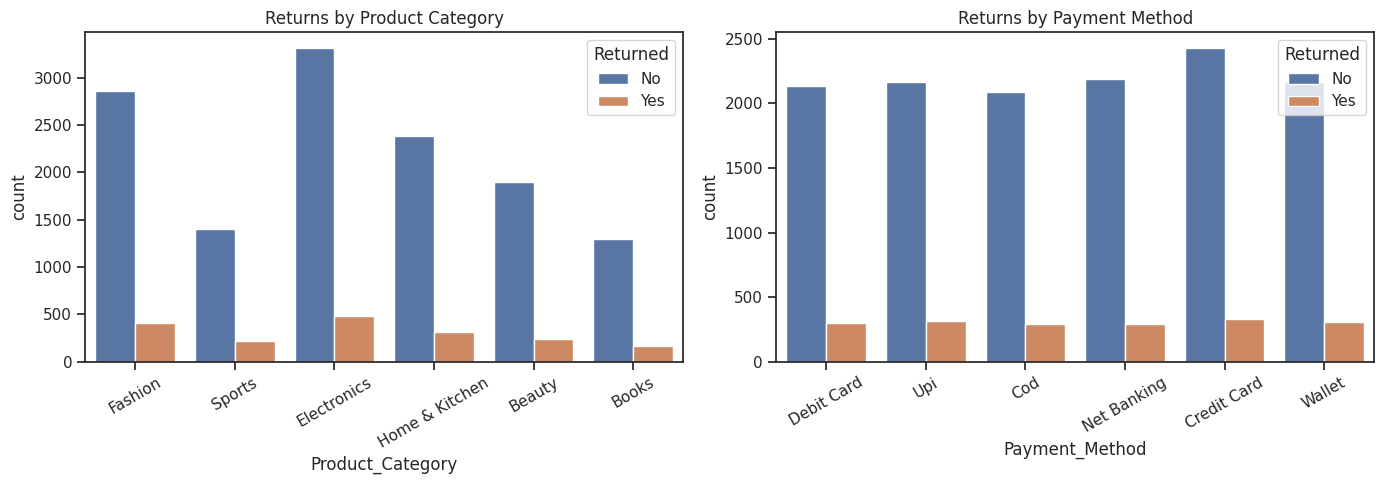

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=orders, x="Product_Category", hue="Returned", ax=axes[0])
axes[0].set_title("Returns by Product Category")
axes[0].tick_params(axis="x", rotation=30)

sns.countplot(data=orders, x="Payment_Method", hue="Returned", ax=axes[1])
axes[1].set_title("Returns by Payment Method")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


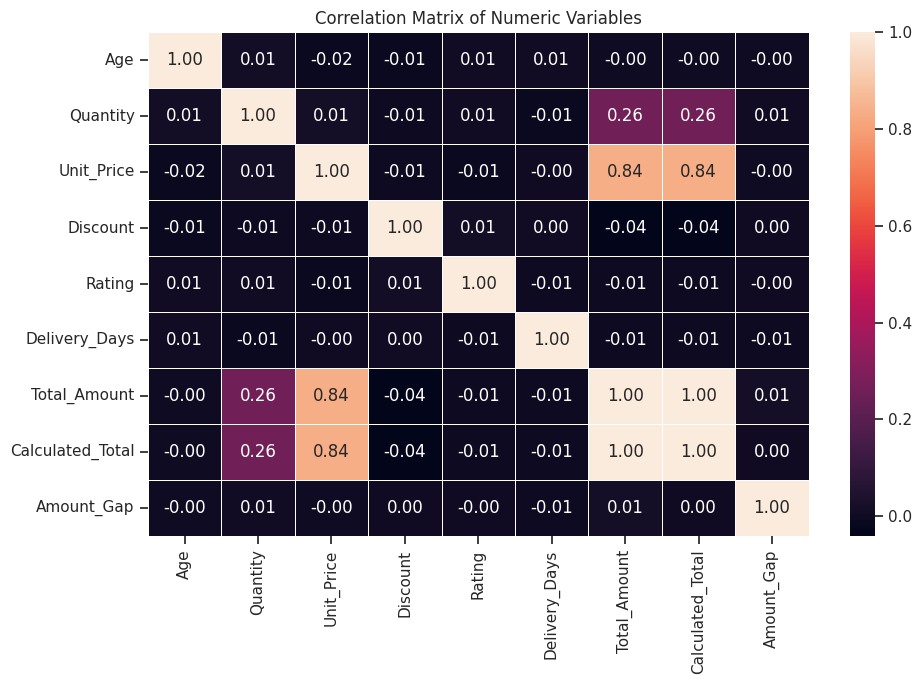

Correlations with Total_Amount:
Total_Amount        1.000
Calculated_Total    1.000
Unit_Price          0.835
Quantity            0.256
Amount_Gap          0.013
Age                -0.004
Delivery_Days      -0.007
Rating             -0.008
Discount           -0.041
Name: Total_Amount, dtype: float64


In [26]:
numeric_corr = orders.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_corr, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.show()

print("Correlations with Total_Amount:")
print(numeric_corr["Total_Amount"].sort_values(ascending=False).round(3))


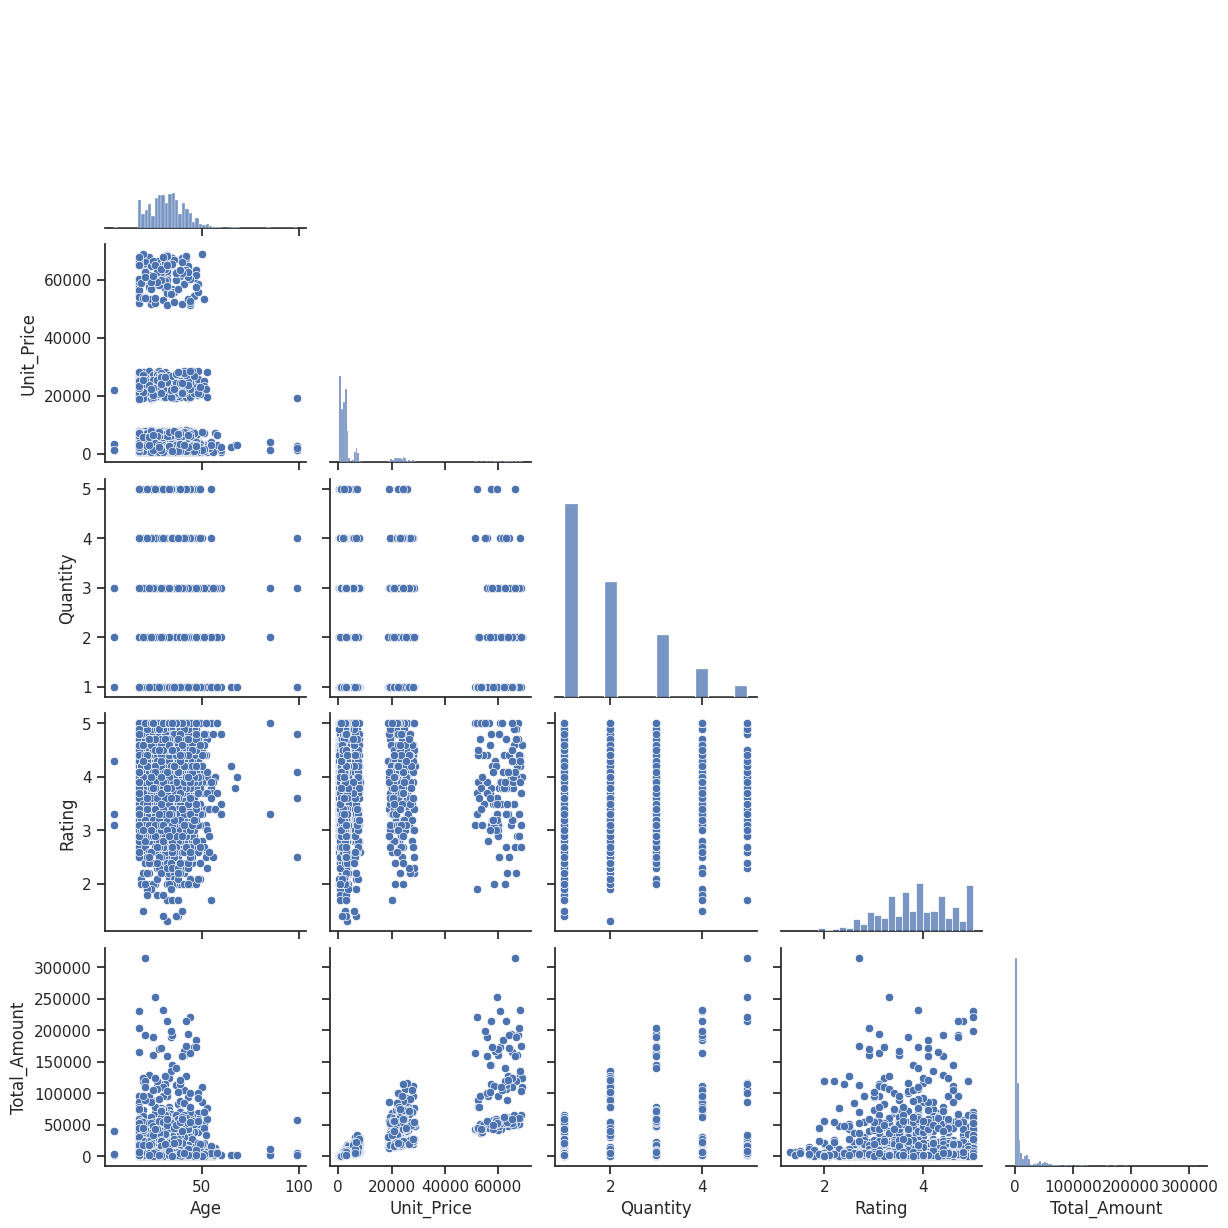

In [27]:
pair_fields = ["Age", "Unit_Price", "Quantity", "Rating", "Total_Amount"]
sns.pairplot(orders[pair_fields].sample(min(2500, len(orders)), random_state=42), corner=True)
plt.show()


In [28]:
top_category = orders["Product_Category"].value_counts().idxmax()
top_payment = orders["Payment_Method"].value_counts().idxmax()
avg_order = orders["Total_Amount"].mean()
median_order = orders["Total_Amount"].median()
return_share = (orders["Returned"].eq("Yes").mean() * 100)

print(f"Most frequent product category : {top_category}")
print(f"Most frequent payment method  : {top_payment}")
print(f"Average order value           : {avg_order:,.2f}")
print(f"Median order value            : {median_order:,.2f}")
print(f"Return share                  : {return_share:.2f}%")


Most frequent product category : Electronics
Most frequent payment method  : Credit Card
Average order value           : 12,565.93
Median order value            : 3,226.92
Return share                  : 12.21%
